# Import Dependecies

In [75]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay

# Import and Load Dataset

In [76]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


In [77]:
os.listdir(path)

['Titanic-Dataset.csv']

In [78]:
df = pd.read_csv(os.path.join(path, 'Titanic-Dataset.csv'))

# Data Understanding

In [79]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [81]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [82]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


### Data Visualisation

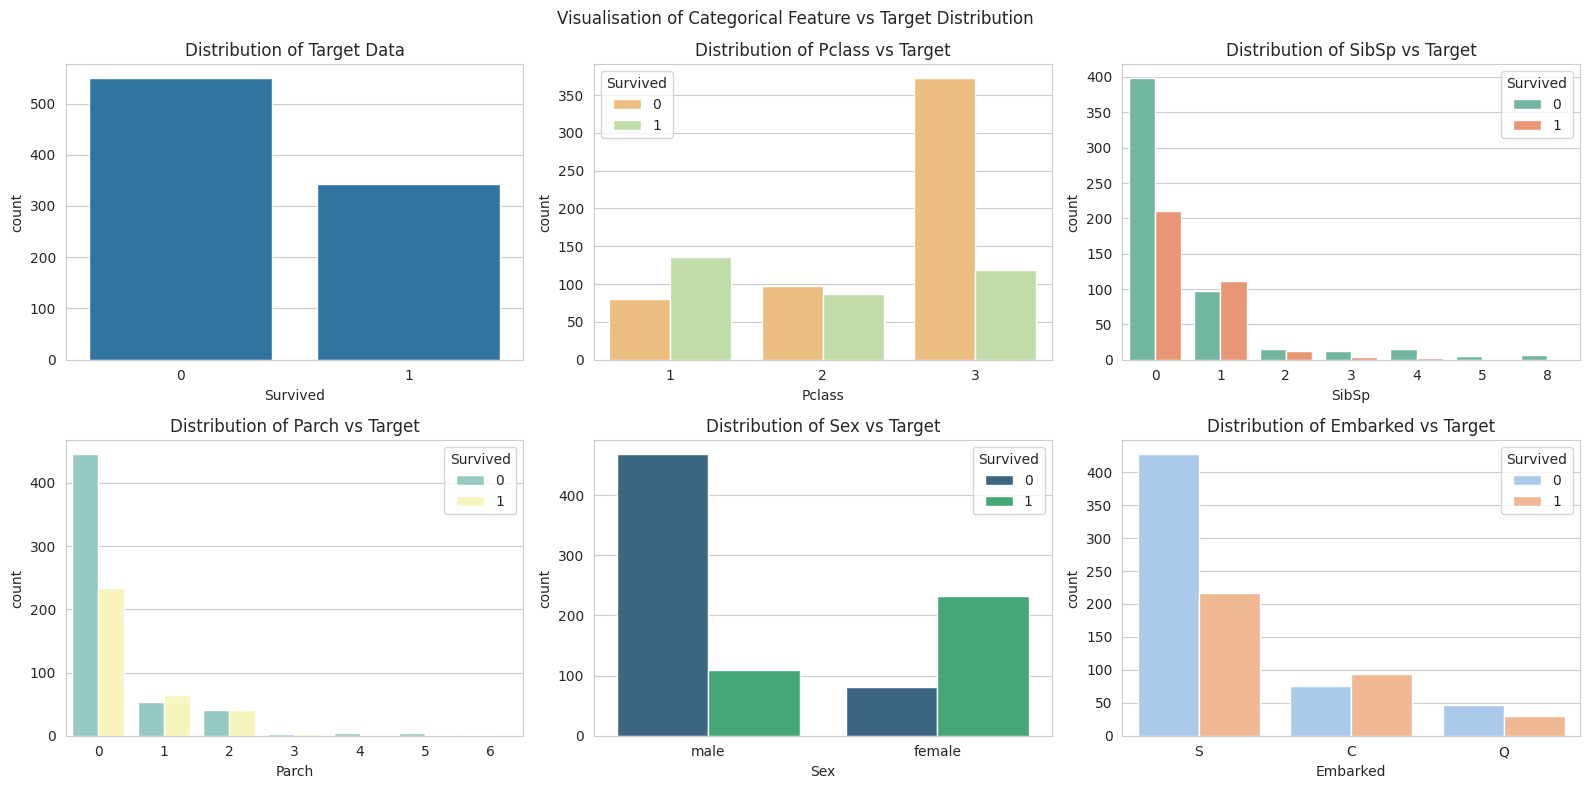

In [83]:
fig, axes = plt.subplots(2,3, figsize=(16,8))

sns.countplot(x='Survived', data=df, ax=axes[0][0])
axes[0][0].set_title('Distribution of Target Data')

sns.countplot(x='Pclass', hue='Survived', palette='Spectral', data=df, ax=axes[0][1])
axes[0][1].set_title('Distribution of Pclass vs Target')

sns.countplot(x='SibSp', hue='Survived', palette='Set2', data=df, ax=axes[0][2])
axes[0][2].set_title('Distribution of SibSp vs Target')

sns.countplot(x='Parch', hue='Survived', palette='Set3', data=df, ax=axes[1][0])
axes[1][0].set_title('Distribution of Parch vs Target')

sns.countplot(x='Sex', hue='Survived', palette='viridis', data=df, ax=axes[1][1])
axes[1][1].set_title('Distribution of Sex vs Target')

sns.countplot(x='Embarked', hue='Survived', palette='pastel', data=df, ax=axes[1][2])
axes[1][2].set_title('Distribution of Embarked vs Target')

plt.suptitle('Visualisation of Categorical Feature vs Target Distribution')
plt.tight_layout()
plt.show()

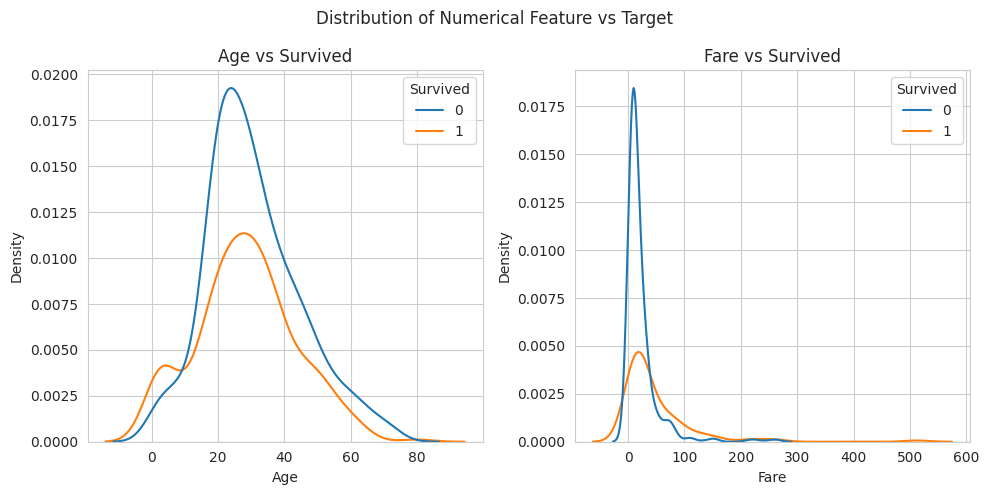

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.kdeplot(x='Age', hue='Survived', data=df, ax=axes[0])
axes[0].set_title('Age vs Survived')
sns.kdeplot(x='Fare', hue='Survived', data=df, ax=axes[1])
axes[1].set_title('Fare vs Survived')
plt.suptitle('Distribution of Numerical Feature vs Target')
plt.tight_layout()

# Data Cleaning

### Drop the columns that's not correlated with the target

In [85]:
df.drop('Cabin', axis=1, inplace=True)

In [86]:
df.drop('PassengerId', axis=1, inplace=True)

In [87]:
df.drop('Name', axis=1, inplace=True)

In [88]:
df.drop('Ticket', axis=1, inplace=True)

### Convert Age column dtype to int

In [89]:
df['Age'] = np.floor(pd.to_numeric(df['Age'], errors='coerce')).astype('Int64')

In [90]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22,1,0,7.2500,S
1,1,1,female,38,1,0,71.2833,C
2,1,3,female,26,0,0,7.9250,S
3,1,1,female,35,1,0,53.1000,S
4,0,3,male,35,0,0,8.0500,S


# Data Preprocessing

### Feature Selection

In [ ]:
num_cat_feat = ['Pclass', 'SibSp', 'Parch'] # Impute Most Frequent
str_cat_feat = ['Sex', 'Embarked'] # Impute Most Frequent + Encode
num_feat = ['Age', 'Fare'] # Impute median + Scale

### Train Test Split

In [92]:
X = df.drop('Survived', axis=1)
y = df['Survived']

In [93]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

### Preprocessing Pipeline and Transformer

In [94]:
num_cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
])

str_cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder())
])

num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [95]:
preprocessor = ColumnTransformer([
    ('num_cat', num_cat_pipe, num_cat_feat),
    ('str_cat', str_cat_pipe, str_cat_feat),
    ('num', num_pipe, num_feat)
], remainder='passthrough')

# Modeling

### Creating LR Model

In [96]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression())
])

### Train LR Model

In [97]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num_cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['Pclass', 'SibSp', 'Parch']),
                                                 ('str_cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder())]),
                                                  ['Sex', 'Embarked']),
                                                 ('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Fare'])])),
                ('model', LogisticRegression())])

# Model Evaluation

### Classification Metrics

In [98]:
y_pred = model.predict(X_test)

In [99]:
accuracy_score(y_test, y_pred)

0.8044692737430168

In [100]:
precision_score(y_test, y_pred)

0.7931034482758621

In [101]:
recall_score(y_test, y_pred)

0.6666666666666666

In [102]:
f1_score(y_test, y_pred)

0.7244094488188977

In [103]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



### Confusion Matrix

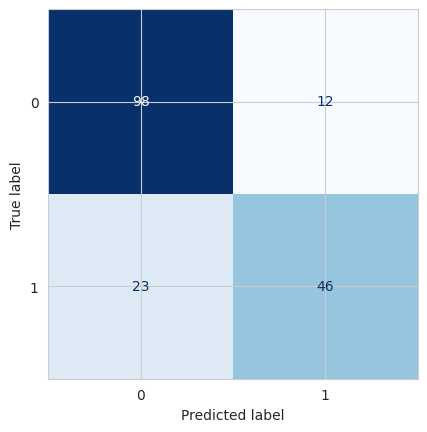

In [104]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, colorbar=False, cmap='Blues');

### 1 Feature Prediction

In [105]:
data = {'Pclass':[2],
        'Sex':['male'],
        'Age':[31.0],
        'SibSp':[1],
        'Parch':[1],
        'Fare':[37.0042],
        'Embarked':['C']}

In [106]:
data

{'Pclass': [2],
 'Sex': ['male'],
 'Age': [31.0],
 'SibSp': [1],
 'Parch': [1],
 'Fare': [37.0042],
 'Embarked': ['C']}

In [107]:
X_val = pd.DataFrame(data)
y_val = y_test.iloc[13]

Predicted Class

In [108]:
model.predict(X_val)

array([0])

Actual Class

In [109]:
y_val

np.int64(0)